# Validation of the synthetic refugee dataset

**Metrics**

| Type | Metric | Meaning |
|---|---|---|
| Categorical | Total variation distance (TVD) | Half the sum of absolute differences between shares; 0 = identical, 1 = no overlap |
| Categorical | Jensen–Shannon distance | Symmetric, bounded information-theoretic distance (base 2, 0 to 1) |
| Categorical | Hellinger distance | Distance between square roots of the shares (0 to 1) |
| Categorical | Chi-square goodness of fit | p-value of the test "the sample comes from the target shares" |
| Continuous | Kolmogorov–Smirnov | Largest gap between the empirical and the true CDF, with p-value |
| Continuous | Wasserstein-1 | Average amount (in years) the distribution must be shifted to match |
| Continuous | Mean and SD | Difference from the target mean and the true SD |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.spatial.distance import jensenshannon

import synthetic_data_generator as gen

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 160)
rng = np.random.default_rng(2026)
B = 1000          # samples for the noise thresholds

df = pd.read_csv("synthetic_refugees.csv")
n = len(df)
targets = gen.target_distributions()
print(f"{n:,} rows, {df.shape[1]} columns")
df.head()

5,000 rows, 13 columns


,refugee_id,sex,age,country_of_origin,education_level,school_years,vocational_training,german_speaking,free_case,religion,assigned_state,true_employment_prob,employed
0,1,female,24.8,Afghanistan,high,13.8,False,none,False,Sunnite,BY,0.1066,0
1,2,male,35.1,Afghanistan,high,11.7,True,good,False,Shiite,BB,0.1848,0
2,3,female,38.0,Syria,low,9.8,False,none,False,Shiite,BE,0.0405,0
3,4,female,23.5,Syria,high,11.5,False,none,True,No religion,HE,0.1708,0
4,5,male,19.7,Syria,low,9.3,False,none,False,Shiite,HB,0.1574,1


## Categorical attributes

In [2]:
def tvd(p, q):       return 0.5 * np.abs(p - q).sum()
def hellinger(p, q): return np.sqrt(0.5 * ((np.sqrt(p) - np.sqrt(q)) ** 2).sum())
def jsd(p, q):       return jensenshannon(p, q, base=2)

METRICS = {"TVD": tvd, "Jensen-Shannon": jsd, "Hellinger": hellinger}

def observed_shares(column, levels):
    counts = df[column].value_counts().reindex(levels, fill_value=0)
    return counts.to_numpy(), counts.to_numpy() / n

def noise_threshold(q, metric, size, quantile=0.95):
    samples = rng.multinomial(size, q, size=B) / size
    return np.quantile([metric(s, q) for s in samples], quantile)

categorical = ["sex", "vocational_training", "free_case", "country_of_origin", "education_level",
               "german_speaking", "religion", "assigned_state"]
rows = []
for column in categorical:
    levels = list(targets[column])
    q = np.array([targets[column][l] for l in levels])
    if column in ("vocational_training", "free_case"):           # booleans are read as True/False
        df[column] = df[column].astype(bool)
    counts, p = observed_shares(column, levels)
    row = {"attribute": column, "categories": len(levels)}
    for name, metric in METRICS.items():
        value, threshold = metric(p, q), noise_threshold(q, metric, n)
        row[name] = round(value, 4)
        row[f"{name} threshold"] = round(threshold, 4)
    row["chi2 p-value"] = round(stats.chisquare(counts, n * q).pvalue, 3)
    row["pass"] = all(row[m] <= row[f"{m} threshold"] for m in METRICS) and row["chi2 p-value"] > 0.05
    rows.append(row)
categorical_results = pd.DataFrame(rows).set_index("attribute")
categorical_results

,categories,TVD,TVD threshold,Jensen-Shannon,Jensen-Shannon threshold,Hellinger,Hellinger threshold,chi2 p-value,pass
attribute,,,,,,,,,
sex,2,0.0094,0.0134,0.0082,0.0117,0.0068,0.0097,0.174,True
vocational_training,2,0.0004,0.0126,0.0004,0.0123,0.0003,0.0102,0.948,True
free_case,2,0.0026,0.0132,0.0022,0.0116,0.0018,0.0098,0.712,True
country_of_origin,9,0.0100,0.0190,0.0147,0.0238,0.0123,0.0198,0.655,True
education_level,3,0.0106,0.0152,0.0093,0.0148,0.0078,0.0121,0.297,True
german_speaking,4,0.0014,0.0070,0.0028,0.0171,0.0023,0.0139,0.976,True
religion,9,0.0173,0.0187,0.0191,0.0234,0.0159,0.0198,0.232,True
assigned_state,16,0.0154,0.0270,0.0187,0.0301,0.0156,0.0252,0.845,True


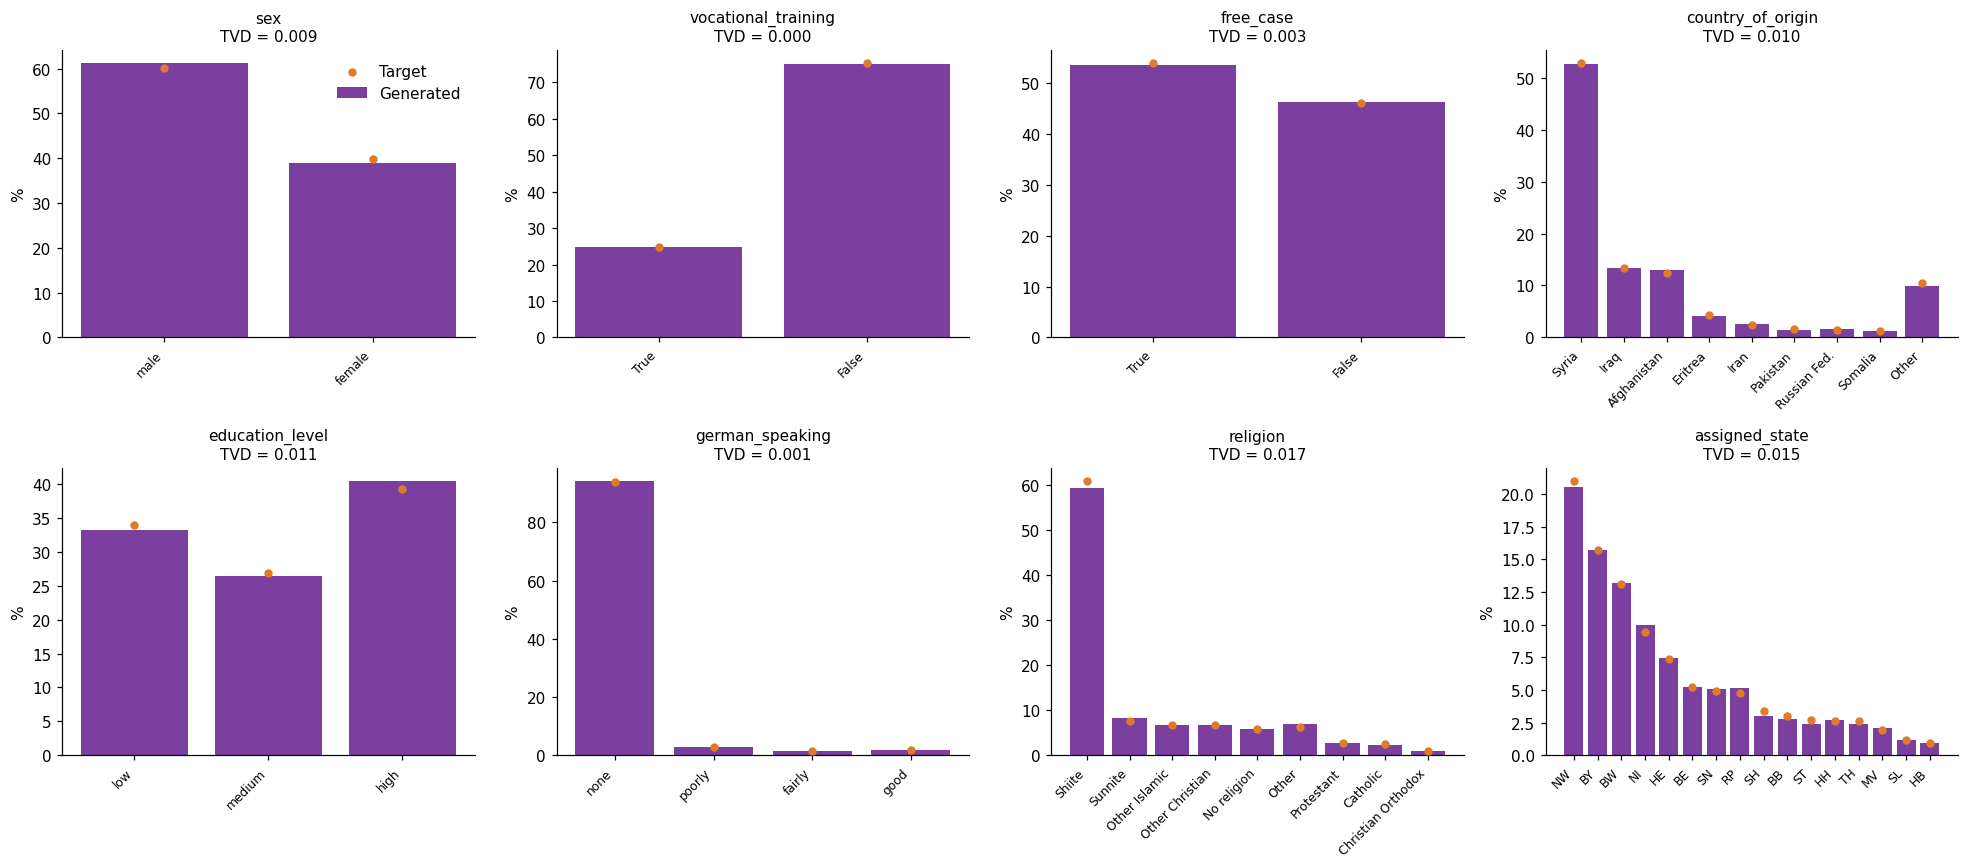

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, column in zip(axes.ravel(), categorical):
    levels = list(targets[column])
    q = np.array([targets[column][l] for l in levels]) * 100
    _, p = observed_shares(column, levels)
    x = np.arange(len(levels))
    ax.bar(x, p * 100, color="#7B3FA0", label="Generated")
    ax.scatter(x, q, color="#E07B28", zorder=3, s=20, label="Target")
    ax.set_xticks(x, [str(l) for l in levels], rotation=45, ha="right", fontsize=8)
    ax.set_title(f"{column}\nTVD = {categorical_results.loc[column, 'TVD']:.3f}", fontsize=10)
    ax.set_ylabel("%")
axes[0, 0].legend(frameon=False)
plt.tight_layout(); plt.show()

## Continuous attributes (age, years of school)

In [4]:
def true_dist(params):
    a, b, loc, scale = gen.truncated_normal_params(**params)
    return stats.truncnorm(a, b, loc=loc, scale=scale)

rows, reference = [], {}
for column in ("age", "school_years"):
    params = targets[column]
    dist = true_dist(params)
    x = df[column].to_numpy()
    reference[column] = dist.rvs(size=200_000, random_state=rng)
    ks = stats.kstest(x, dist.cdf)
    w = stats.wasserstein_distance(x, reference[column])
    # noise thresholds from samples of the same size, rounded to one decimal like the data
    sims = [np.round(dist.rvs(size=n, random_state=rng), 1) for _ in range(300)]
    ks_thr = np.quantile([stats.kstest(s, dist.cdf).statistic for s in sims], 0.95)
    w_thr = np.quantile([stats.wasserstein_distance(s, reference[column]) for s in sims], 0.95)
    rows.append({
        "attribute": column,
        "mean (target)": f"{x.mean():.2f} ({params['mean']})",
        "SD (true)": f"{x.std():.2f} ({dist.std():.2f})",
        "KS statistic": round(ks.statistic, 4), "KS threshold": round(ks_thr, 4),
        "KS p-value": round(ks.pvalue, 3),
        "Wasserstein (years)": round(w, 4), "Wasserstein threshold": round(w_thr, 4),
        "pass": ks.statistic <= ks_thr and w <= w_thr,
    })
continuous_results = pd.DataFrame(rows).set_index("attribute")
continuous_results

,mean (target),SD (true),KS statistic,KS threshold,KS p-value,Wasserstein (years),Wasserstein threshold,pass
attribute,,,,,,,,
age,31.96 (32.0),8.22 (8.23),0.0116,0.0204,0.509,0.0844,0.2447,True
school_years,9.95 (9.9),2.98 (2.95),0.0202,0.0243,0.033,0.0669,0.0952,True


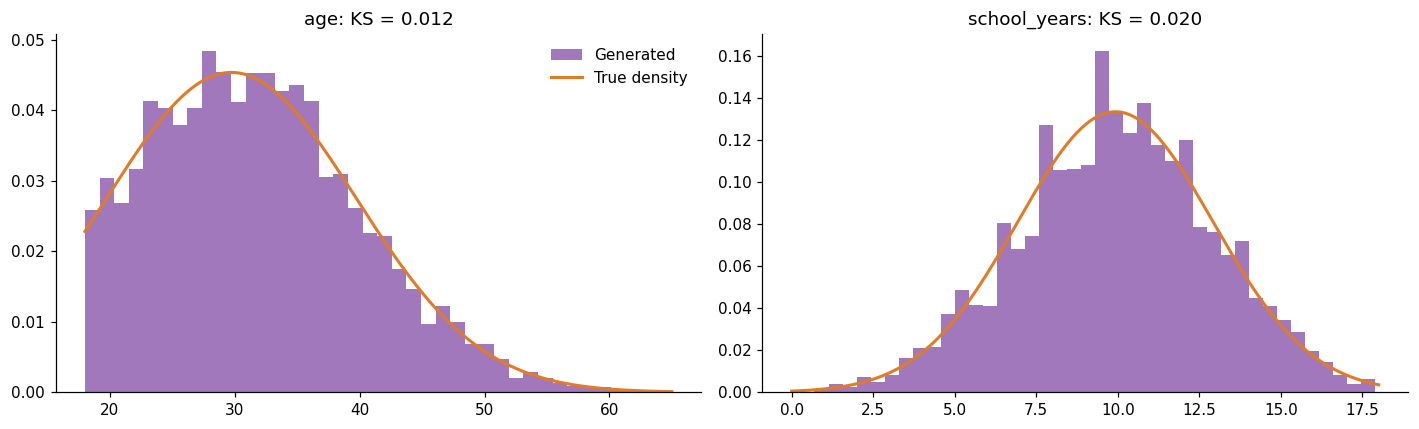

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, column in zip(axes, ("age", "school_years")):
    dist = true_dist(targets[column])
    grid = np.linspace(targets[column]["low"], targets[column]["high"], 400)
    ax.hist(df[column], bins=40, density=True, color="#7B3FA0", alpha=.7, label="Generated")
    ax.plot(grid, dist.pdf(grid), color="#E07B28", lw=2, label="True density")
    ax.set_title(f"{column}: KS = {continuous_results.loc[column, 'KS statistic']:.3f}")
axes[0].legend(frameon=False); plt.tight_layout(); plt.show()

## Dependencies between attributes

Table 5 (Strasser) gives only marginals, so the two dependencies are generator design choices. Here we check that the data reproduce what the generator intends:

- education level * years of school (Gaussian copula): rank correlation and mean school years per level, compared with a 200,000-person reference sample from the generator;
- religion given country of origin (iterative proportional fitting): TVD between observed and intended religion shares within each origin, weighted by origin size.

In [6]:
big = gen.sample_attributes(200_000, np.random.default_rng(7))
rank = {"low": 0, "medium": 1, "high": 2}
def spearman(d): return d["education_level"].map(rank).corr(d["school_years"], method="spearman")

edu = pd.DataFrame({
    "generated": df.groupby("education_level")["school_years"].mean(),
    "reference": big.groupby("education_level")["school_years"].mean(),
}).loc[["low", "medium", "high"]].round(2)
sims = [spearman(big.sample(n, random_state=i)) for i in range(300)]
print(f"Spearman correlation: {spearman(df):.3f} (reference {spearman(big):.3f}, "
      f"95% noise band {np.quantile(sims, .025):.3f} to {np.quantile(sims, .975):.3f})")
edu

Spearman correlation: 0.512 (reference 0.530, 95% noise band 0.508 to 0.551)


,generated,reference
education_level,,
low,8.06,7.99
medium,9.77,9.79
high,11.62,11.63


In [7]:
conditional = gen.religion_given_origin()
religions = list(gen.RELIGION)
rows, weighted_obs, weighted_thr = [], 0, 0
for i, origin in enumerate(gen.ORIGINS):
    members = df[df["country_of_origin"] == origin]
    m = len(members)
    p = members["religion"].value_counts().reindex(religions, fill_value=0).to_numpy() / m
    d, thr = tvd(p, conditional[i]), noise_threshold(conditional[i], tvd, m)
    weighted_obs += d * m / n; weighted_thr += thr * m / n
    rows.append({"origin": origin, "n": m, "TVD": round(d, 3), "threshold": round(thr, 3),
                 "most common religion": religions[int(np.argmax(p))]})
religion_results = pd.DataFrame(rows).set_index("origin")
print(f"Weighted TVD {weighted_obs:.3f}, weighted threshold {weighted_thr:.3f}")
religion_results

Weighted TVD 0.031, weighted threshold 0.041


,n,TVD,threshold,most common religion
origin,,,,
Syria,2635,0.030,0.027,Shiite
Iraq,671,0.007,0.027,Shiite
Afghanistan,649,0.017,0.032,Shiite
Eritrea,203,0.052,0.108,Other Christian
Iran,127,0.026,0.072,Shiite
Pakistan,73,0.069,0.085,Shiite
Russian Fed.,80,0.157,0.180,Sunnite
Somalia,63,0.101,0.178,Sunnite
Other,499,0.038,0.064,Shiite


## Outcome model calibration

The outcome model is calibrated to three targets: overall employment of 15%, a women-to-men ratio of 0.41 (IAB) and the relative employment level of each state (Bundesagentur für Arbeit). We check them on `true_employment_prob` (no Bernoulli noise) and on the realised `employed` column.

In [8]:
male = df["sex"] == "male"
p = df["true_employment_prob"]
ratio = p[~male].mean() / p[male].mean()
print(f"mean true probability: {p.mean():.4f} (target 0.15)")
print(f"realised employment:   {df['employed'].mean():.4f} "
      f"(95% binomial band {0.15 - 1.96*np.sqrt(.15*.85/n):.4f} to {0.15 + 1.96*np.sqrt(.15*.85/n):.4f})")
print(f"women / men ratio:     {ratio:.3f} (target {31/75:.3f})")

q = gen.normalise(gen.STATE_QUOTA)
level = np.array([gen.TARGETS["state_relative_level"][s] for s in gen.STATES])
target_rate = level * 0.15 / (q @ level)
obs = df.groupby("assigned_state")["true_employment_prob"].mean().reindex(gen.STATES)
cnt = df["assigned_state"].value_counts().reindex(gen.STATES)
state_check = pd.DataFrame({"people": cnt, "observed": obs.round(4), "target": target_rate.round(4),
                            "difference (pp)": ((obs - target_rate) * 100).round(2)})
print(f"mean absolute difference across states: {state_check['difference (pp)'].abs().mean():.2f} pp")
state_check.T

mean true probability: 0.1511 (target 0.15)
realised employment:   0.1522 (95% binomial band 0.1401 to 0.1599)
women / men ratio:     0.406 (target 0.413)
mean absolute difference across states: 0.44 pp


assigned_state,NW,BY,BW,NI,HE,BE,SN,RP,SH,BB,ST,HH,TH,MV,SL,HB
people,1028.0000,786.0000,660.0000,500.0000,373.0000,263.0000,255.0000,257.0000,151.0000,141.0000,121.0000,136.0000,120.0000,106.0000,57.0000,46.0000
observed,0.1442,0.1682,0.1558,0.1478,0.1425,0.1540,0.1430,0.1489,0.1597,0.1343,0.1414,0.1686,0.1480,0.1381,0.1342,0.1484
target,0.1474,0.1657,0.1579,0.1438,0.1450,0.1495,0.1391,0.1486,0.1453,0.1325,0.1322,0.1642,0.1501,0.1337,0.1352,0.1388
difference (pp),-0.3200,0.2500,-0.2100,0.4000,-0.2500,0.4500,0.3900,0.0300,1.4300,0.1900,0.9300,0.4400,-0.2100,0.4400,-0.0900,0.9700


## Do the distances shrink with sample size?

If the generator is correct, every distance should shrink like 1/√n (pure sampling noise). A distance that stops shrinking would point to a systematic error. We generate datasets of increasing size and plot TVD per attribute on log-log axes; the dashed line shows the 1/√n slope.

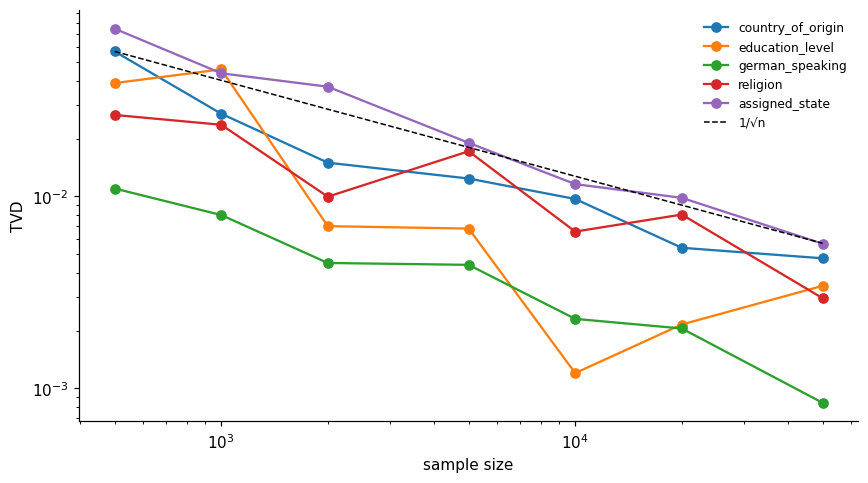

In [9]:
sizes = [500, 1000, 2000, 5000, 10000, 20000, 50000]
truth = gen.GroundTruth()
curves = {c: [] for c in ["country_of_origin", "education_level", "german_speaking", "religion", "assigned_state"]}
for size in sizes:
    d = gen.generate(size, seed=size, truth=truth)
    for column in curves:
        levels = list(targets[column]); q_ = np.array([targets[column][l] for l in levels])
        p_ = d[column].value_counts().reindex(levels, fill_value=0).to_numpy() / size
        curves[column].append(tvd(p_, q_))
fig, ax = plt.subplots(figsize=(8, 4.5))
for column, values in curves.items():
    ax.plot(sizes, values, "o-", label=column)
ref = np.array(sizes, float)
ax.plot(ref, curves["country_of_origin"][0] * np.sqrt(sizes[0] / ref), "k--", lw=1, label="1/√n")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("sample size"); ax.set_ylabel("TVD")
ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

##  Summary

In [10]:
summary = pd.concat([
    categorical_results[["TVD", "TVD threshold", "chi2 p-value", "pass"]].rename(
        columns={"TVD": "distance", "TVD threshold": "threshold", "chi2 p-value": "p-value"}).assign(metric="TVD"),
    continuous_results[["KS statistic", "KS threshold", "KS p-value", "pass"]].rename(
        columns={"KS statistic": "distance", "KS threshold": "threshold", "KS p-value": "p-value"}).assign(metric="KS"),
])
print(f"{summary['pass'].sum()} of {len(summary)} attributes pass")
summary[["metric", "distance", "threshold", "p-value", "pass"]]

10 of 10 attributes pass


,metric,distance,threshold,p-value,pass
attribute,,,,,
sex,TVD,0.0094,0.0134,0.174,True
vocational_training,TVD,0.0004,0.0126,0.948,True
free_case,TVD,0.0026,0.0132,0.712,True
country_of_origin,TVD,0.0100,0.0190,0.655,True
education_level,TVD,0.0106,0.0152,0.297,True
german_speaking,TVD,0.0014,0.0070,0.976,True
religion,TVD,0.0173,0.0187,0.232,True
assigned_state,TVD,0.0154,0.0270,0.845,True
age,KS,0.0116,0.0204,0.509,True


- All checks compare the data with the distributions the generator **intends**. They show that the sampling code is correct; they cannot show that Table 5 itself is correct.
- **Religion:** the shares in Table 5 (Shiite 60.6%, Sunnite 7.6%) look swapped. Because the generator matches these marginals exactly, most Syrians come out as Shiite. This needs to be checked against the original table.
- The dependencies in Section 3 are modelling choices; the check only confirms that the data follow them.